In [1]:
# Install required packages
!pip install xgboost imbalanced-learn -q

# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, classification_report)
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("✓ Setup complete!")
print(f"Pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")

✓ Setup complete!
Pandas: 2.2.2
NumPy: 1.26.4


In [2]:
file_1 = 'Downloads/salmonella_dna/genes_kmers_labels.csv'
file_2 = 'Downloads/salmonella_dna/snps_only_labels.csv'
file_3 = 'Downloads/salmonella_dna/snps_kmers_labels.csv'
file_4 = 'Downloads/salmonella_dna/genes_snps_labels.csv'

In [3]:
# Configuration
CONFIG = {
    'n_folds': 6,
    'random_state': 42,
    'smote_strategy': 0.5,  # Oversample resistant to 50% of majority class
    'top_n_features': 30,
    
    # Files to process
    'datasets': {
        'Genes + SNPs': file_1,
        'SNPs Only': file_2,
        'SNPs + K-mers': file_3,
        'Genes + K-mers': file_4
    }
}

print("Configuration:")
for key, value in CONFIG.items():
    if key != 'datasets':
        print(f"  {key}: {value}")

print(f"\nDatasets to process: {len(CONFIG['datasets'])}")

Configuration:
  n_folds: 6
  random_state: 42
  smote_strategy: 0.5
  top_n_features: 30

Datasets to process: 4


In [4]:
def load_and_validate_data(filepath):
    """Load CSV and validate structure"""
    df = pd.read_csv(filepath)
    
    # Separate features and labels
    X = df.drop(columns=['Genome_ID', 'Pefloxacin_Phenotype'])
    y = df['Pefloxacin_Phenotype']
    genome_ids = df['Genome_ID']
    
    # Validate
    assert len(X) == len(y), "Mismatch in samples"
    assert y.isin([0, 1]).all(), "Labels must be 0 or 1"
    
    print(f"  ✓ Loaded: {len(X)} samples × {X.shape[1]} features")
    print(f"    Susceptible (0): {(y==0).sum()} ({(y==0).sum()/len(y)*100:.1f}%)")
    print(f"    Resistant (1): {(y==1).sum()} ({(y==1).sum()/len(y)*100:.1f}%)")
    
    return X, y, genome_ids, df.columns.tolist()

def get_models(scale_pos_weight):
    """Define all models with class imbalance handling"""
    return {
        'XGBoost': XGBClassifier(
            n_estimators=100,
            max_depth=3,
            learning_rate=0.1,
            scale_pos_weight=scale_pos_weight,
            subsample=0.8,
            colsample_bytree=0.5,
            reg_alpha=1,
            reg_lambda=1,
            random_state=CONFIG['random_state'],
            eval_metric='logloss'
        ),
        'RandomForest': RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            min_samples_split=5,
            min_samples_leaf=2,
            class_weight='balanced',
            random_state=CONFIG['random_state']
        ),
        'ExtraTrees': ExtraTreesClassifier(
            n_estimators=100,
            max_depth=10,
            min_samples_split=5,
            min_samples_leaf=2,
            class_weight='balanced',
            random_state=CONFIG['random_state']
        ),
        'GradientBoosting': GradientBoostingClassifier(
            n_estimators=100,
            max_depth=3,
            learning_rate=0.1,
            random_state=CONFIG['random_state']
        )
    }

def train_and_evaluate(X, y, models, use_smote=False, dataset_name=""):
    """Train models with cross-validation"""
    
    skf = StratifiedKFold(n_splits=CONFIG['n_folds'], shuffle=True, 
                          random_state=CONFIG['random_state'])
    
    results = {name: [] for name in models.keys()}
    
    print(f"\n{'='*70}")
    print(f"Training: {dataset_name} {'WITH SMOTE' if use_smote else 'BASELINE'}")
    print(f"{'='*70}")
    
    for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), 1):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        # Apply SMOTE if requested
        if use_smote:
            smote = SMOTE(sampling_strategy=CONFIG['smote_strategy'], 
                         random_state=CONFIG['random_state'])
            X_train, y_train = smote.fit_resample(X_train, y_train)
        
        print(f"\nFold {fold}/{CONFIG['n_folds']}:")
        print(f"  Train: {len(y_train)} ({(y_train==1).sum()} resistant)")
        print(f"  Test: {len(y_test)} ({(y_test==1).sum()} resistant)")
        
        for model_name, model in models.items():
            # Train
            model.fit(X_train, y_train)
            
            # Predict
            y_pred = model.predict(X_test)
            
            # Metrics
            acc = accuracy_score(y_test, y_pred)
            prec = precision_score(y_test, y_pred, zero_division=0)
            rec = recall_score(y_test, y_pred, zero_division=0)
            f1 = f1_score(y_test, y_pred, zero_division=0)
            
            results[model_name].append({
                'fold': fold,
                'accuracy': acc,
                'precision': prec,
                'recall': rec,
                'f1': f1
            })
            
            print(f"    {model_name:20s} Acc={acc:.3f}, F1={f1:.3f}, Rec={rec:.3f}")
    
    return results

def summarize_results(results):
    """Calculate average metrics across folds"""
    summary = {}
    
    for model_name, scores in results.items():
        df = pd.DataFrame(scores)
        summary[model_name] = {
            'accuracy': df['accuracy'].mean(),
            'accuracy_std': df['accuracy'].std(),
            'precision': df['precision'].mean(),
            'precision_std': df['precision'].std(),
            'recall': df['recall'].mean(),
            'recall_std': df['recall'].std(),
            'f1': df['f1'].mean(),
            'f1_std': df['f1'].std()
        }
    
    return summary

print("✓ Helper functions loaded")

✓ Helper functions loaded


In [5]:
# Store all results
all_results = {}

for dataset_name, filepath in CONFIG['datasets'].items():
    
    print(f"\n\n{'#'*70}")
    print(f"# PROCESSING: {dataset_name}")
    print(f"# File: {filepath}")
    print(f"{'#'*70}")
    
    # Load data
    X, y, genome_ids, feature_names = load_and_validate_data(filepath)
    
    # Calculate scale_pos_weight
    scale_pos_weight = (y==0).sum() / (y==1).sum()
    
    # Get models
    models = get_models(scale_pos_weight)
    
    # Train baseline (no SMOTE)
    baseline_results = train_and_evaluate(X, y, models, use_smote=False, 
                                         dataset_name=dataset_name)
    
    # Train with SMOTE
    smote_results = train_and_evaluate(X, y, models, use_smote=True, 
                                      dataset_name=dataset_name)
    
    # Store results
    all_results[dataset_name] = {
        'baseline': baseline_results,
        'smote': smote_results,
        'n_features': X.shape[1],
        'n_samples': len(X)
    }

print("\n\n✓ All training complete!")



######################################################################
# PROCESSING: Genes + SNPs
# File: Downloads/salmonella_dna/genes_kmers_labels.csv
######################################################################
  ✓ Loaded: 338 samples × 5136 features
    Susceptible (0): 295 (87.3%)
    Resistant (1): 43 (12.7%)

Training: Genes + SNPs BASELINE

Fold 1/6:
  Train: 281 (36 resistant)
  Test: 57 (7 resistant)
    XGBoost              Acc=0.754, F1=0.364, Rec=0.571
    RandomForest         Acc=0.702, F1=0.320, Rec=0.571
    ExtraTrees           Acc=0.667, F1=0.296, Rec=0.571
    GradientBoosting     Acc=0.860, F1=0.200, Rec=0.143

Fold 2/6:
  Train: 281 (35 resistant)
  Test: 57 (8 resistant)
    XGBoost              Acc=0.754, F1=0.462, Rec=0.750
    RandomForest         Acc=0.719, F1=0.429, Rec=0.750
    ExtraTrees           Acc=0.719, F1=0.429, Rec=0.750
    GradientBoosting     Acc=0.877, F1=0.222, Rec=0.125

Fold 3/6:
  Train: 282 (36 resistant)
  Test: 56 (7 resistan

In [6]:
# Create comparison table
comparison_data = []

for dataset_name, results in all_results.items():
    baseline_summary = summarize_results(results['baseline'])
    smote_summary = summarize_results(results['smote'])
    
    for model_name in baseline_summary.keys():
        baseline_f1 = baseline_summary[model_name]['f1']
        smote_f1 = smote_summary[model_name]['f1']
        improvement = ((smote_f1 - baseline_f1) / baseline_f1) * 100
        
        comparison_data.append({
            'Dataset': dataset_name,
            'Model': model_name,
            'Features': results['n_features'],
            'Baseline F1': baseline_f1,
            'SMOTE F1': smote_f1,
            'Improvement (%)': improvement,
            'Baseline Recall': baseline_summary[model_name]['recall'],
            'SMOTE Recall': smote_summary[model_name]['recall']
        })

comparison_df = pd.DataFrame(comparison_data)

# Display
print("\n" + "="*100)
print("COMPLETE RESULTS COMPARISON")
print("="*100)
print(comparison_df.to_string(index=False))

# Find best performer
best_row = comparison_df.loc[comparison_df['SMOTE F1'].idxmax()]
print("\n" + "="*100)
print("🏆 BEST PERFORMER:")
print("="*100)
print(f"Dataset: {best_row['Dataset']}")
print(f"Model: {best_row['Model']}")
print(f"F1-Score: {best_row['SMOTE F1']:.3f}")
print(f"Recall: {best_row['SMOTE Recall']:.3f}")
print(f"Features: {best_row['Features']}")
print(f"Improvement over baseline: +{best_row['Improvement (%)']:.1f}%")

# Check if target met
if best_row['SMOTE F1'] >= 0.81:
    print("\n✅ TARGET ACHIEVED! F1 ≥ 81%")
else:
    gap = (0.81 - best_row['SMOTE F1']) * 100
    print(f"\n⚠️ Gap to target: {gap:.1f} percentage points")


COMPLETE RESULTS COMPARISON
       Dataset            Model  Features  Baseline F1  SMOTE F1  Improvement (%)  Baseline Recall  SMOTE Recall
  Genes + SNPs          XGBoost      5136     0.397702  0.292191       -26.530185         0.601190      0.767857
  Genes + SNPs     RandomForest      5136     0.340083  0.424518        24.827916         0.553571      0.601190
  Genes + SNPs       ExtraTrees      5136     0.339851  0.383030        12.705288         0.625000      0.553571
  Genes + SNPs GradientBoosting      5136     0.305976  0.386195        26.217331         0.211310      0.330357
     SNPs Only          XGBoost      5555     0.563476  0.503327       -10.674697         0.863095      0.863095
     SNPs Only     RandomForest      5555     0.563016  0.552897        -1.797348         0.839286      0.750000
     SNPs Only       ExtraTrees      5555     0.575891  0.572558        -0.578655         0.863095      0.773810
     SNPs Only GradientBoosting      5555     0.642347  0.533697   

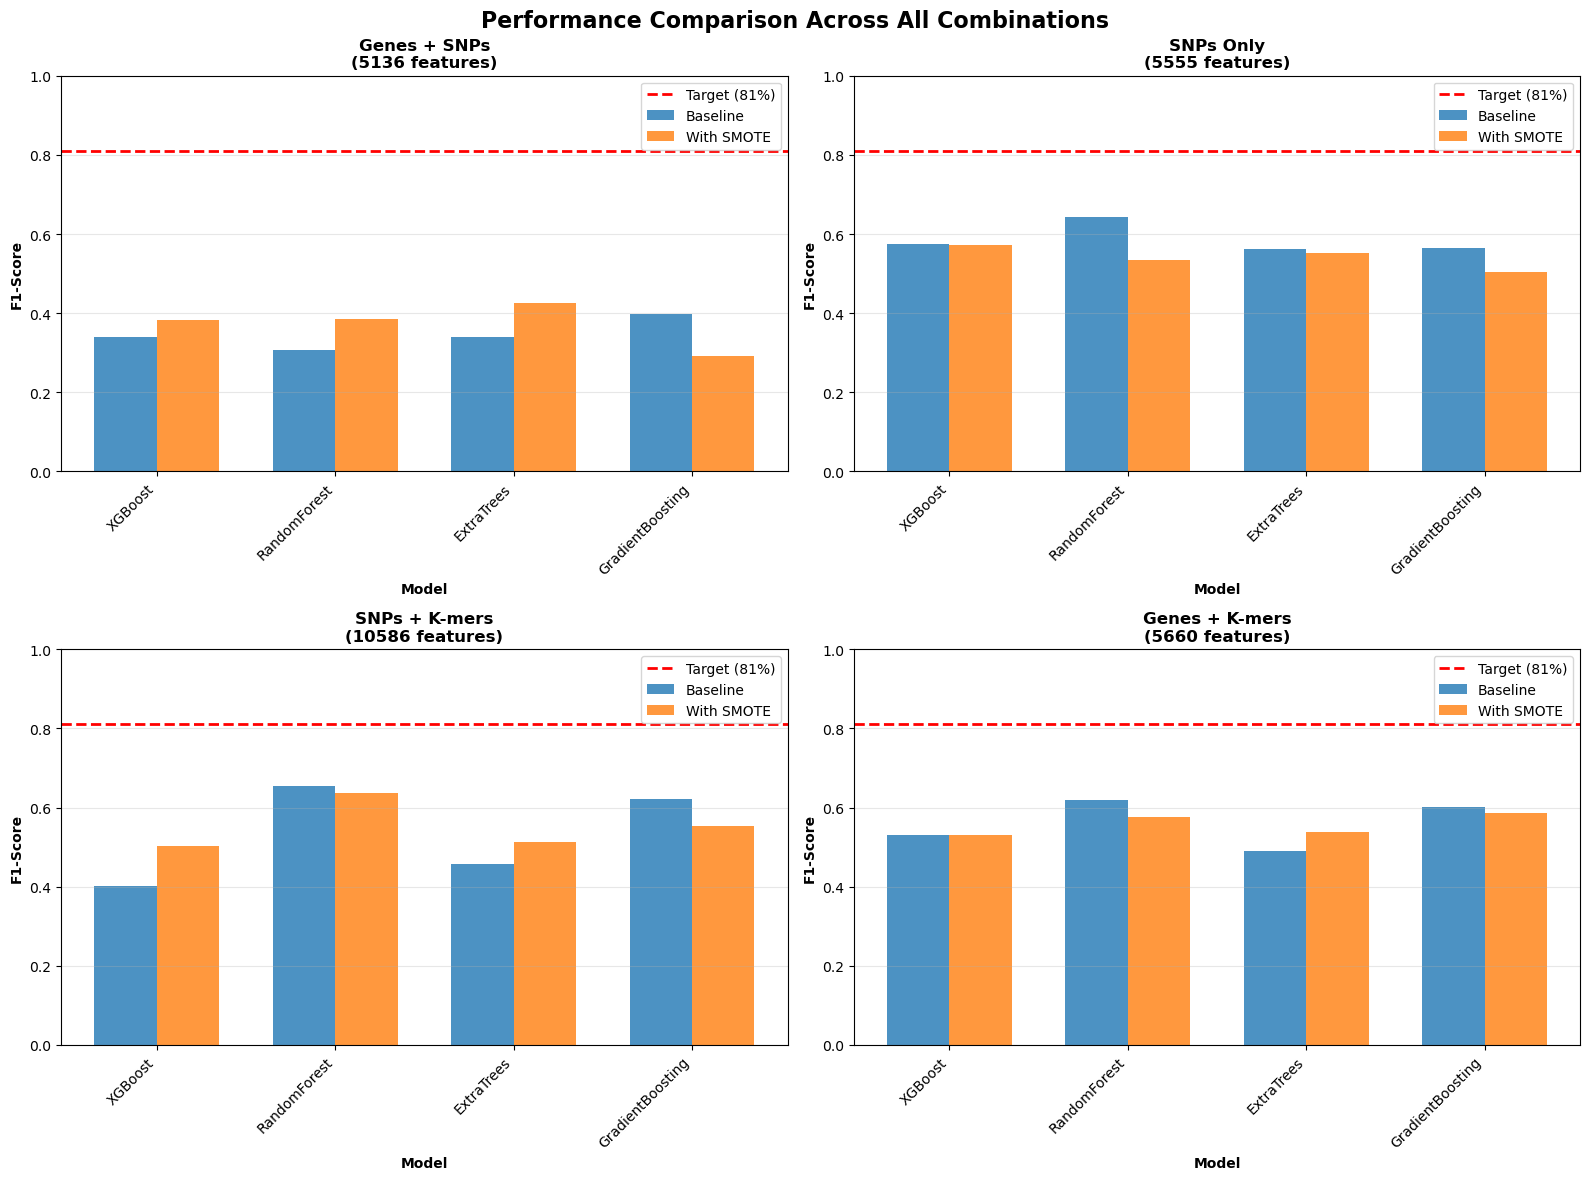

✓ Saved: performance_comparison.png


<Figure size 640x480 with 0 Axes>

In [7]:
# Create visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Performance Comparison Across All Combinations', fontsize=16, fontweight='bold')

datasets = list(CONFIG['datasets'].keys())

for idx, dataset in enumerate(datasets):
    row = idx // 2
    col = idx % 2
    ax = axes[row, col]
    
    # Extract data for this dataset
    dataset_data = comparison_df[comparison_df['Dataset'] == dataset]
    
    x = np.arange(len(dataset_data['Model'].unique()))
    width = 0.35
    
    baseline_f1 = dataset_data.groupby('Model')['Baseline F1'].first().values
    smote_f1 = dataset_data.groupby('Model')['SMOTE F1'].first().values
    
    bars1 = ax.bar(x - width/2, baseline_f1, width, label='Baseline', alpha=0.8)
    bars2 = ax.bar(x + width/2, smote_f1, width, label='With SMOTE', alpha=0.8)
    
    # Add target line
    ax.axhline(y=0.81, color='r', linestyle='--', label='Target (81%)', linewidth=2)
    
    ax.set_xlabel('Model', fontweight='bold')
    ax.set_ylabel('F1-Score', fontweight='bold')
    ax.set_title(f'{dataset}\n({dataset_data["Features"].iloc[0]} features)', fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(dataset_data['Model'].unique(), rotation=45, ha='right')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    ax.set_ylim([0, 1])

plt.tight_layout()
plt.show()

# Save figure
plt.savefig('performance_comparison.png', dpi=300, bbox_inches='tight')
print("✓ Saved: performance_comparison.png")


FEATURE IMPORTANCE ANALYSIS
Dataset: SNPs + K-mers
Model: GradientBoosting
  ✓ Loaded: 338 samples × 10586 features
    Susceptible (0): 295 (87.3%)
    Resistant (1): 43 (12.7%)

Top 20 Most Important Features:
Rank   Feature                                            Importance  
----------------------------------------------------------------------
1      NC_003197_3437381_A>T                              0.378787
2      NC_003197_3442838_G>A                              0.131562
3      NC_003197_3720797_T>G                              0.056778
4      IALAEPGVES                                         0.049329
5      LTLWLPLYKR                                         0.035493
6      AVRLLGRENN                                         0.032687
7      QTDYVHAAII                                         0.026470
8      ALAEPGVESV                                         0.024473
9      LKGRGVACPE                                         0.021453
10     NC_003197_3841479_C>T              

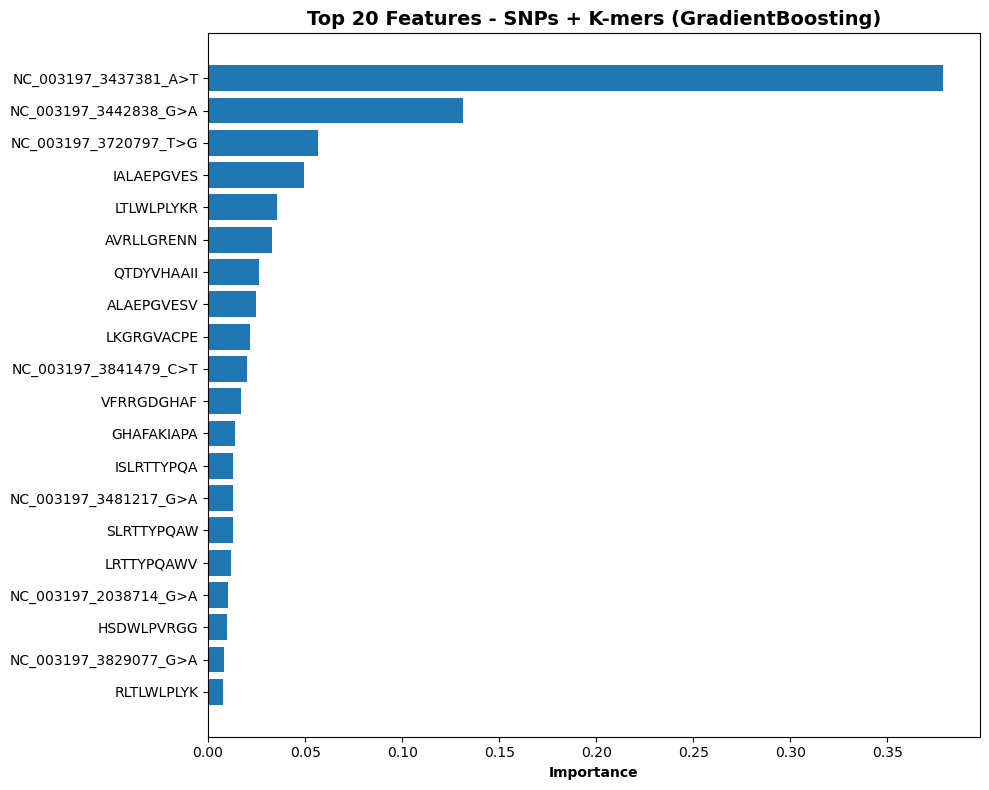


✓ Saved: feature_importance.png


<Figure size 640x480 with 0 Axes>

In [8]:
# Train final model on best combination
best_dataset = best_row['Dataset']
best_model_name = best_row['Model']

print(f"\n{'='*70}")
print(f"FEATURE IMPORTANCE ANALYSIS")
print(f"Dataset: {best_dataset}")
print(f"Model: {best_model_name}")
print(f"{'='*70}")

# Load best dataset
filepath = CONFIG['datasets'][best_dataset]
X, y, genome_ids, feature_names = load_and_validate_data(filepath)
feature_list = [f for f in feature_names if f not in ['Genome_ID', 'Pefloxacin_Phenotype']]

# Apply SMOTE
smote = SMOTE(sampling_strategy=CONFIG['smote_strategy'], random_state=CONFIG['random_state'])
X_resampled, y_resampled = smote.fit_resample(X, y)

# Train final model
scale_pos_weight = (y==0).sum() / (y==1).sum()
models = get_models(scale_pos_weight)
final_model = models[best_model_name]
final_model.fit(X_resampled, y_resampled)

# Get feature importance
if hasattr(final_model, 'feature_importances_'):
    importances = final_model.feature_importances_
    indices = np.argsort(importances)[::-1]
    
    print(f"\nTop 20 Most Important Features:")
    print(f"{'Rank':<6} {'Feature':<50} {'Importance':<12}")
    print("-" * 70)
    
    for i in range(min(20, len(indices))):
        idx = indices[i]
        print(f"{i+1:<6} {feature_list[idx]:<50} {importances[idx]:.6f}")
    
    # Visualize top 20
    top_n = 20
    top_indices = indices[:top_n]
    top_features = [feature_list[i] for i in top_indices]
    top_importances = importances[top_indices]
    
    plt.figure(figsize=(10, 8))
    plt.barh(range(top_n), top_importances[::-1])
    plt.yticks(range(top_n), top_features[::-1])
    plt.xlabel('Importance', fontweight='bold')
    plt.title(f'Top {top_n} Features - {best_dataset} ({best_model_name})', 
              fontweight='bold', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
    print("\n✓ Saved: feature_importance.png")

In [9]:
# Export detailed results to CSV
comparison_df.to_csv('training_results_summary.csv', index=False)
print("✓ Saved: training_results_summary.csv")

# Export best model's top features
if hasattr(final_model, 'feature_importances_'):
    importance_df = pd.DataFrame({
        'Feature': [feature_list[i] for i in indices],
        'Importance': importances[indices]
    })
    importance_df.to_csv('feature_importance_ranking.csv', index=False)
    print("✓ Saved: feature_importance_ranking.csv")



✓ Saved: training_results_summary.csv
✓ Saved: feature_importance_ranking.csv
